In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from graph_utils import generate_sample_graph
from route_planner import dijkstra
from traffic_analysis import bellman_ford
from connectivity_module import bfs_traversal, dfs_traversal
from mst_planner import prim_mst, kruskal_mst


# Smart City Traffic System - Algorithm Analysis
This notebook runs experiments on random connected graphs of different sizes (10, 25, 50, 100 nodes) to compare the performance of various manual graph algorithms.


In [2]:
sizes = [10, 25, 50, 100]
graphs = {}

# Generate graphs
for size in sizes:
    graphs[size] = generate_sample_graph(size)
    print(f"Graph with {size} nodes has {graphs[size].number_of_edges()} edges.")


Graph with 10 nodes has 10 edges.
Graph with 25 nodes has 34 edges.
Graph with 50 nodes has 83 edges.
Graph with 100 nodes has 105 edges.


,Nodes,BFS Time (s),DFS Time (s)
0,10,0.000014,0.000013
1,25,0.000014,0.000020
2,50,0.000025,0.000040
3,100,0.000044,0.000070


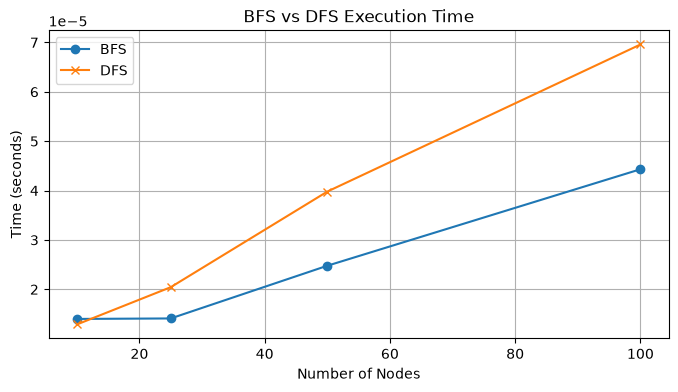

In [3]:
bfs_times = []
dfs_times = []

for size in sizes:
    g = graphs[size]
    start_node = list(g.nodes())[0]
    
    # BFS
    start_time = time.perf_counter()
    bfs_traversal(g, start_node)
    bfs_times.append(time.perf_counter() - start_time)
    
    # DFS
    start_time = time.perf_counter()
    dfs_traversal(g, start_node)
    dfs_times.append(time.perf_counter() - start_time)

df_traversal = pd.DataFrame({
    'Nodes': sizes,
    'BFS Time (s)': bfs_times,
    'DFS Time (s)': dfs_times
})

display(df_traversal)

plt.figure(figsize=(8, 4))
plt.plot(sizes, bfs_times, marker='o', label='BFS')
plt.plot(sizes, dfs_times, marker='x', label='DFS')
plt.xlabel('Number of Nodes')
plt.ylabel('Time (seconds)')
plt.title('BFS vs DFS Execution Time')
plt.legend()
plt.grid(True)
plt.show()


,Nodes,Edges,Route Length (edges),Dijkstra Time (s),Bellman-Ford Time (s)
0,10,10,1,0.000052,0.000068
1,25,34,1,0.000056,0.000125
2,50,83,3,0.000303,0.000326
3,100,105,1,0.000293,0.000448


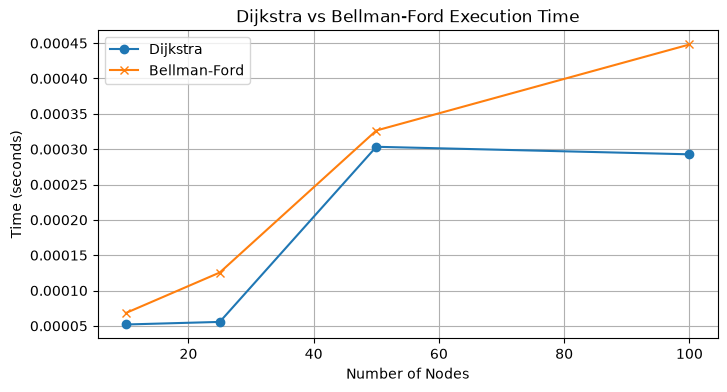

In [4]:
dijkstra_times = []
bf_times = []
route_lengths = []

for size in sizes:
    g = graphs[size]
    nodes = list(g.nodes())
    src, dst = nodes[0], nodes[-1]
    
    # Dijkstra
    start_time = time.perf_counter()
    path_d, _, _ = dijkstra(g, src, dst)
    dijkstra_times.append(time.perf_counter() - start_time)
    
    # Bellman-Ford
    start_time = time.perf_counter()
    path_b, _, _ = bellman_ford(g, src, dst)
    bf_times.append(time.perf_counter() - start_time)
    
    route_lengths.append(len(path_d) - 1 if path_d else 0)

df_shortest_path = pd.DataFrame({
    'Nodes': sizes,
    'Edges': [graphs[s].number_of_edges() for s in sizes],
    'Route Length (edges)': route_lengths,
    'Dijkstra Time (s)': dijkstra_times,
    'Bellman-Ford Time (s)': bf_times
})

display(df_shortest_path)

plt.figure(figsize=(8, 4))
plt.plot(sizes, dijkstra_times, marker='o', label='Dijkstra')
plt.plot(sizes, bf_times, marker='x', label='Bellman-Ford')
plt.xlabel('Number of Nodes')
plt.ylabel('Time (seconds)')
plt.title('Dijkstra vs Bellman-Ford Execution Time')
plt.legend()
plt.grid(True)
plt.show()


,Nodes,Edges,Prim Time (s),Kruskal Time (s)
0,10,10,0.000061,0.000043
1,25,34,0.000166,0.000060
2,50,83,0.000743,0.000136
3,100,105,0.002341,0.000203


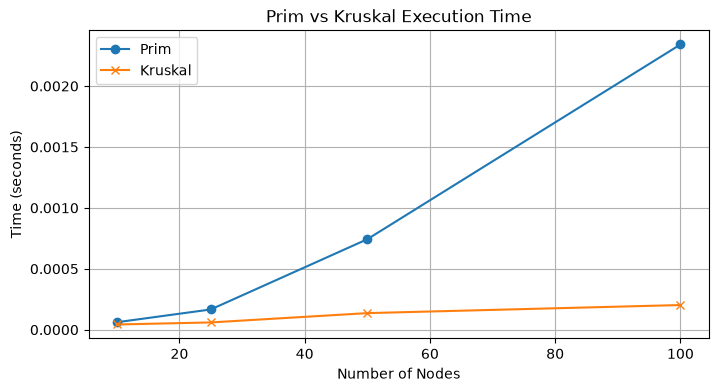

In [5]:
prim_times = []
kruskal_times = []

for size in sizes:
    g = graphs[size]
    
    # Prim
    start_time = time.perf_counter()
    prim_mst(g)
    prim_times.append(time.perf_counter() - start_time)
    
    # Kruskal
    start_time = time.perf_counter()
    kruskal_mst(g)
    kruskal_times.append(time.perf_counter() - start_time)

df_mst = pd.DataFrame({
    'Nodes': sizes,
    'Edges': [graphs[s].number_of_edges() for s in sizes],
    'Prim Time (s)': prim_times,
    'Kruskal Time (s)': kruskal_times
})

display(df_mst)

plt.figure(figsize=(8, 4))
plt.plot(sizes, prim_times, marker='o', label='Prim')
plt.plot(sizes, kruskal_times, marker='x', label='Kruskal')
plt.xlabel('Number of Nodes')
plt.ylabel('Time (seconds)')
plt.title('Prim vs Kruskal Execution Time')
plt.legend()
plt.grid(True)
plt.show()


### Discussion: Algorithm Suitability for Traffic Management

1. **Routing Algorithms (Dijkstra vs Bellman-Ford):**
   - **Dijkstra** is substantially faster, particularly as the network grows, making it highly suitable for standard route queries (like GPS navigation) where speed is prioritized.
   - **Bellman-Ford** takes more time due to its edge relaxation approach. However, it is essential in scenarios where negative weights might exist (e.g., modeling tolls or credits, although less common in pure physical traffic) or for certain distributed routing protocols. In general traffic management, Dijkstra or A* is preferred over Bellman-Ford.
   
2. **Connectivity (BFS vs DFS):**
   - Both operate in linear time $O(V + E)$ and show similar raw execution times.
   - **BFS** is ideal for analyzing reachability by distance/hops (e.g., finding the nearest emergency services or analyzing cascading congestion zones). 
   - **DFS** is less useful for finding short paths, but can be useful for topological sorting or cycle detection in complex flow networks.
   
3. **Infrastructure Planning (Prim vs Kruskal for MST):**
   - **Kruskal's** algorithm performance heavily depends on the edge sorting step ($O(E \log E)$). For sparse city road networks, it's very efficient.
   - **Prim's** algorithm performance depends on the priority queue implementation (we used a simple search which is $O(V^2)$). For denser networks, an optimized Prim (with min-heap) is excellent.
   - In traffic management, MSTs are useful for laying out physical infrastructure (e.g., minimizing the cost of laying fiber optics connecting traffic lights or deploying a power grid for EV stations).
